# Лабораторная работа №1: Регрессия

**Датасет:** Wine Quality (UCI). Красные и белые вина объединены в одну таблицу, тип вина закодирован признаком `is_red`.

**Цель:** пройти полный цикл решения задачи регрессии: EDA, подготовка данных, baseline, feature engineering, обучение моделей, сравнение, интерпретация и анализ ошибок.

**Основная метрика:** RMSE.  
**Порог:** RMSE < 0.70.

Логика работы:

1. Загружаем данные и делаем первичный EDA.
2. Сразу делим данные на train и test.
3. Все решения принимаем по кросс-валидации на train.
4. Test используем только для финальной оценки.
5. Постепенно улучшаем линейную модель:
   - базовая Linear Regression;
   - Linear Regression на полиномиальных признаках;
   - Ridge с регуляризацией.
6. Сравниваем с Random Forest и Gradient Boosting (с симметричным тюнингом).
7. Анализируем важность признаков и ошибки, включая проверку на «чистом» test (без копий из train).

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ssl

ssl._create_default_https_context = ssl._create_unverified_context

from pathlib import Path

from scipy.stats import loguniform

from sklearn.model_selection import (
    KFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Загрузка данных и первичный EDA

Загружаем красные и белые вина, объединяем их в один датафрейм и добавляем признак `is_red`.

In [29]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"

red_path = Path("winequality-red.csv")
white_path = Path("winequality-white.csv")

if red_path.exists():
    red = pd.read_csv(red_path, sep=";")
else:
    red = pd.read_csv(DATA_URL + "winequality-red.csv", sep=";")

if white_path.exists():
    white = pd.read_csv(white_path, sep=";")
else:
    white = pd.read_csv(DATA_URL + "winequality-white.csv", sep=";")

red["is_red"] = 1
white["is_red"] = 0

data = pd.concat([red, white], ignore_index=True)

print("Красное вино:", red.shape)
print("Белое вино:", white.shape)
print("Объединённый датасет:", data.shape)

data.head()

Красное вино: (1599, 13)
Белое вино: (4898, 13)
Объединённый датасет: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Пропуски: 0
Полных дубликатов: 1177


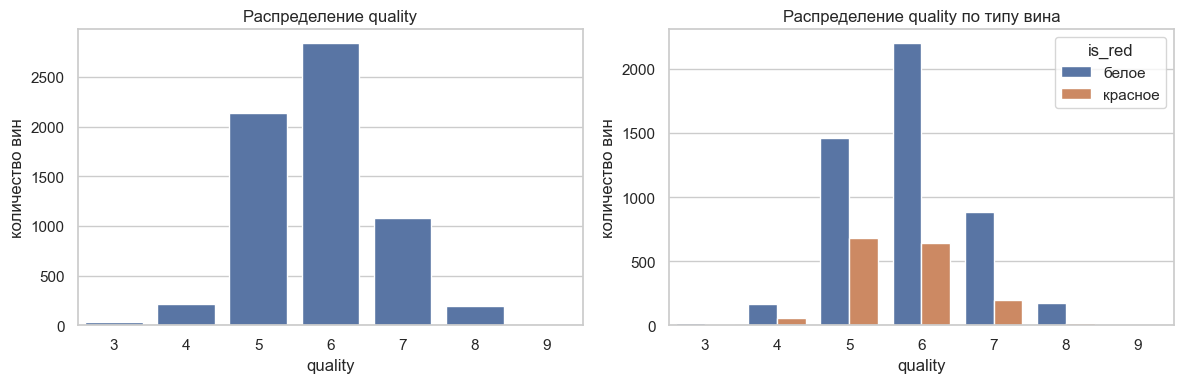

quality
3    0.0046
4    0.0332
5    0.3291
6    0.4365
7    0.1661
8    0.0297
9    0.0008
Name: proportion, dtype: float64
        count   mean    std
is_red                     
0        4898  5.878  0.886
1        1599  5.636  0.808


In [30]:
print("Пропуски:", data.isna().sum().sum())
print("Полных дубликатов:", data.duplicated().sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x="quality", ax=ax[0])
ax[0].set_title("Распределение quality")
ax[0].set_xlabel("quality")
ax[0].set_ylabel("количество вин")

sns.countplot(data=data, x="quality", hue="is_red", ax=ax[1])
ax[1].set_title("Распределение quality по типу вина")
ax[1].set_xlabel("quality")
ax[1].set_ylabel("количество вин")
ax[1].legend(title="is_red", labels=["белое", "красное"])

plt.tight_layout()
plt.show()

print(
    data["quality"]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

print(
    data.groupby("is_red")["quality"]
    .agg(["count", "mean", "std"])
    .round(3)
)

C:\Users\Dim4i\AppData\Local\Temp\ipykernel_10976\4264060520.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_with_quality.values, y=corr_with_quality.index, palette="coolwarm")


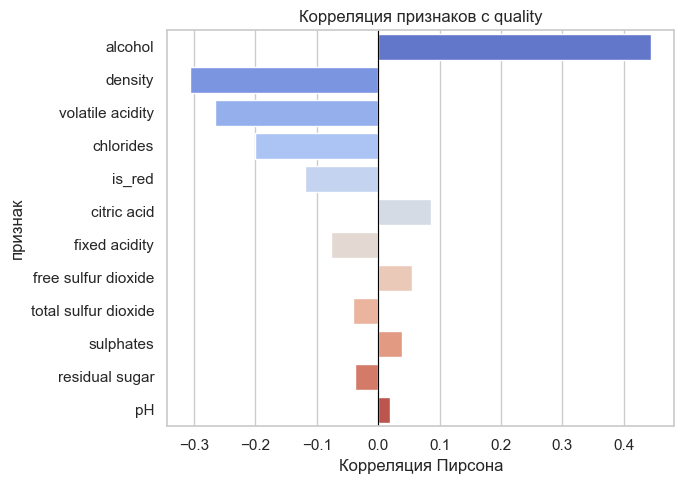

alcohol                 0.444
density                -0.306
volatile acidity       -0.266
chlorides              -0.201
is_red                 -0.119
citric acid             0.086
fixed acidity          -0.077
free sulfur dioxide     0.055
total sulfur dioxide   -0.041
sulphates               0.038
residual sugar         -0.037
pH                      0.020
Name: quality, dtype: float64

In [31]:
corr_with_quality = (
    data.corr(numeric_only=True)["quality"]
    .drop("quality")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

plt.figure(figsize=(7, 5))
sns.barplot(x=corr_with_quality.values, y=corr_with_quality.index, palette="coolwarm")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Корреляция признаков с quality")
plt.xlabel("Корреляция Пирсона")
plt.ylabel("признак")
plt.tight_layout()
plt.show()

corr_with_quality.round(3)

### Выводы по EDA

- Пропусков нет, все признаки числовые.
- Есть полные дубликаты. В учебной работе мы их оставляем, но обязательно проверяем, насколько они влияют на метрики. Если дубликат попал и в train, и в test, модель может «запомнить» объект и дать оптимистичную оценку.
- Целевая переменная `quality` сильно сконцентрирована вокруг значений 5 и 6. Крайние оценки 3, 4, 8 и 9 встречаются редко.
- Наиболее сильные линейные связи с `quality`:
  - `alcohol` — положительная связь;
  - `volatile acidity` — отрицательная связь;
  - `density` — отрицательная связь, но она частично дублирует информацию об алкоголе и остаточном сахаре.
- Для красного и белого вина распределения признаков отличаются, поэтому признак `is_red` может быть полезен модели.

## 2. Подготовка выборок

Делим данные на train и test до построения признаков и обучения моделей.  
Используем стратификацию по `quality`, чтобы в train и test сохранить пропорции редких оценок.

In [32]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
RMSE_TARGET = 0.70

QUALITY_MIN = 3
QUALITY_MAX = 9

SKEWED_FEATURES = [
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "sulphates",
]

In [33]:
X = data.drop(columns=["quality"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nРаспределение quality в train:")
print(y_train.value_counts().sort_index())

print("\nРаспределение quality в test:")
print(y_test.value_counts().sort_index())

Train: (5197, 12)
Test: (1300, 12)

Распределение quality в train:
quality
3      24
4     173
5    1710
6    2269
7     863
8     154
9       4
Name: count, dtype: int64

Распределение quality в test:
quality
3      6
4     43
5    428
6    567
7    216
8     39
9      1
Name: count, dtype: int64


**Размер выборок:** 80% train / 20% test, `random_state=42`. Для ~6.5 тыс. объектов этого достаточно, чтобы и обучить модели, и получить устойчивую оценку.

**Способ разбиения:** случайное, **стратифицированное** по `quality`. Данные не имеют временной структуры, поэтому случайное разбиение допустимо. Стратификация сохраняет долю редких оценок (3, 9) в обеих частях — иначе они могли бы почти полностью оказаться в одной из выборок.

**Подбор гиперпараметров** выполняется кросс-валидацией только на train; test не используется для выбора моделей, признаков и параметров.

**Проблема многократной оценки на одном test:** если выбирать модель или параметры, глядя на test, происходит **утечка данных** — модель неявно «подстраивается» под тест. Итоговая оценка становится оптимистично завышенной и перестаёт честно отражать качество на новых данных. Поэтому test используется **один раз** — для финального сравнения.

## 3. Feature engineering

Для линейных моделей строим расширенное пространство признаков:

1. Логарифмируем признаки с длинным правым хвостом:
   - `residual sugar`;
   - `chlorides`;
   - `free sulfur dioxide`;
   - `total sulfur dioxide`;
   - `sulphates`.

2. Строим полиномиальные признаки второй степени:
   - исходные признаки;
   - квадраты признаков;
   - попарные произведения признаков.

Из 12 признаков получаем 90 признаков.

Деревья умеют находить нелинейности и взаимодействия сами, поэтому RF/GB в итоге обучаем на исходных 12 признаках (см. секцию 6).

In [34]:
def add_log(df):
    df = df.copy()
    for col in SKEWED_FEATURES:
        df[col] = np.log1p(df[col])
    return df


X_train_log = add_log(X_train)
X_test_log = add_log(X_test)

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = pd.DataFrame(
    poly.fit_transform(X_train_log),
    columns=poly.get_feature_names_out(X_train_log.columns),
    index=X_train.index,
)

X_test_poly = pd.DataFrame(
    poly.transform(X_test_log),
    columns=poly.get_feature_names_out(X_train_log.columns),
    index=X_test.index,
)

print("Было признаков:", X_train.shape[1])
print("Стало признаков:", X_train_poly.shape[1])
print("Примеры новых признаков:", X_train_poly.columns[:10].tolist())

Было признаков: 12
Стало признаков: 90
Примеры новых признаков: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates']


## 4. Метрики и схема валидации

Будем использовать:

- **RMSE** — основная метрика;
- **MAE** — дополнительная метрика, менее чувствительная к выбросам;
- **R²** — доля объяснённой дисперсии.

Все решения о моделях и гиперпараметрах принимаем по кросс-валидации на train.  
Test используем только для финальной проверки.

В качестве baseline возьмём константу — среднее значение `quality` по train. Для RMSE оптимальная константа именно средняя, а не медиана.

In [35]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

results = []
predictions = {}
models = {}


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def mae(y_true, y_pred):
    return float(mean_absolute_error(y_true, y_pred))


def clip_pred(y_pred):
    return np.clip(np.asarray(y_pred), QUALITY_MIN, QUALITY_MAX)


def add_result(name, cv_rmse, cv_std, y_pred, feature_set, estimator=None):
    y_pred = clip_pred(y_pred)

    predictions[name] = y_pred
    if estimator is not None:
        models[name] = estimator

    results.append({
        "Модель": name,
        "Признаки": feature_set,
        "CV RMSE": float(cv_rmse),
        "CV std": float(cv_std),
        "Test RMSE": rmse(y_test, y_pred),
        "Test MAE": mae(y_test, y_pred),
        "R2": float(r2_score(y_test, y_pred)),
    })

    return y_pred


def search_cv_stats(search):
    idx = search.best_index_
    cv_rmse = float(-search.cv_results_["mean_test_score"][idx])
    cv_std = float(search.cv_results_["std_test_score"][idx])
    return cv_rmse, cv_std

### Что показывают MAE и RMSE

**MAE (Mean Absolute Error)** — средняя абсолютная ошибка:

$$\text{MAE} = \frac{1}{n}\sum |y_i - \hat{y}_i|$$

Показывает средний «промах» модели в единицах целевой переменной (`quality`). MAE = 0.43 означает, что модель в среднем ошибается на 0.43 балла качества. Метрика интерпретируется напрямую и устойчива к выбросам, но все ошибки весит линейно.

**RMSE (Root Mean Squared Error)** — корень из средней квадратичной ошибки:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$$

Тоже измеряется в единицах `quality`, но перед усреднением ошибки возводятся в квадрат. Из-за этого RMSE **сильнее реагирует на большие ошибки**: ошибка в 2 балла даёт вклад в 4 раза больше, чем ошибка в 1 балл, а в 3 балла — в 9 раз больше. Поэтому RMSE чувствителен к «выбросам» и плохим предсказаниям на редких значениях.

**Почему у одной и той же модели MAE и RMSE заметно различаются:**

- Если ошибки однородные и маленькие — MAE и RMSE близки.
- Если есть крупные промахи (например, модель предсказала 6 вместо 3) — RMSE заметно больше MAE, потому что квадрат усиливает вклад крупных ошибок.

Для задачи с редкими крайними значениями `quality` это особенно важно: RMSE сильнее «наказывает» модель, если она сваливается к среднему на экстремальных винах. Поэтому RMSE — основная метрика, а MAE — вспомогательная и более «человекочитаемая».

## 5. Baseline и линейная регрессия

Сначала считаем baseline — предсказание средним значением `quality` по train.

Затем проверяем линейную модель:

1. `LinearRegression` на исходных признаках;
2. `LinearRegression` на полиномиальных признаках;
3. `Ridge` на полиномиальных признаках с подбором `alpha`.

Логика такая: обычная линейная регрессия скорее всего будет слишком простой, полиномиальные признаки добавят нелинейность, а Ridge не даст переобучиться на большом количестве скоррелированных признаков.

In [36]:
# Baseline
baseline = DummyRegressor(strategy="mean")

baseline_scores = -cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

add_result(
    name="Baseline (среднее train)",
    cv_rmse=baseline_scores.mean(),
    cv_std=baseline_scores.std(),
    y_pred=baseline_pred,
    feature_set="raw",
    estimator=baseline,
)


# Linear Regression на исходных признаках
lr_raw = make_pipeline(
    StandardScaler(), # центрирует и масштабирует признаки
    LinearRegression(),
)

lr_raw_scores = -cross_val_score(
    lr_raw,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

lr_raw.fit(X_train, y_train)
lr_raw_pred = lr_raw.predict(X_test)

add_result(
    name="Linear Regression (raw)",
    cv_rmse=lr_raw_scores.mean(),
    cv_std=lr_raw_scores.std(),
    y_pred=lr_raw_pred,
    feature_set="raw",
    estimator=lr_raw,
)


# Linear Regression на полиномиальных признаках
lr_poly = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)

lr_poly_scores = -cross_val_score(
    lr_poly,
    X_train_poly,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

lr_poly.fit(X_train_poly, y_train)
lr_poly_pred = lr_poly.predict(X_test_poly)

add_result(
    name="Linear Regression (poly)",
    cv_rmse=lr_poly_scores.mean(),
    cv_std=lr_poly_scores.std(),
    y_pred=lr_poly_pred,
    feature_set="poly",
    estimator=lr_poly,
)


print("Baseline CV RMSE:", round(results[0]["CV RMSE"], 4))
print("Linear Regression raw CV RMSE:", round(results[1]["CV RMSE"], 4))
print("Linear Regression poly CV RMSE:", round(results[2]["CV RMSE"], 4))

Baseline CV RMSE: 0.8732
Linear Regression raw CV RMSE: 0.7377
Linear Regression poly CV RMSE: 0.7115


Коэффициенты LinearRegression (raw) после StandardScaler:
density                -0.3230
residual sugar          0.3086
alcohol                 0.2558
volatile acidity       -0.2423
is_red                  0.1335
fixed acidity           0.1121
sulphates               0.1093
total sulfur dioxide   -0.0909
pH                      0.0881
free sulfur dioxide     0.0861
chlorides              -0.0219
citric acid            -0.0136
Name: coef, dtype: float64


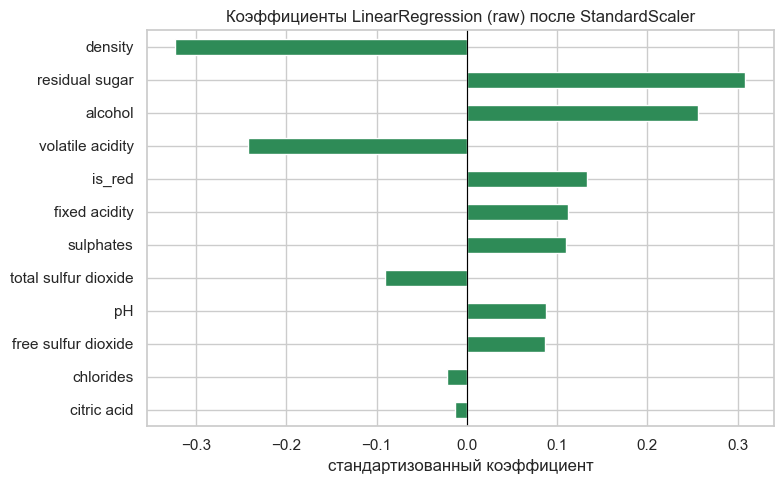

In [37]:
# Коэффициенты LinearRegression (raw) после StandardScaler
lr_raw_coef = pd.Series(
    lr_raw.named_steps["linearregression"].coef_,
    index=X_train.columns,
    name="coef",
).sort_values(key=lambda s: s.abs(), ascending=False)

print("Коэффициенты LinearRegression (raw) после StandardScaler:")
print(lr_raw_coef.round(4))

plt.figure(figsize=(8, 5))
lr_raw_coef.plot.barh(color="seagreen")
plt.gca().invert_yaxis()
plt.title("Коэффициенты LinearRegression (raw) после StandardScaler")
plt.xlabel("стандартизованный коэффициент")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Интерпретация коэффициентов LinearRegression (raw):**

- Мы используем `make_pipeline(StandardScaler(), LinearRegression())`, поэтому коэффициенты **уже стандартизованы** и их можно сравнивать между собой.
- Стандартизованный коэффициент показывает, на сколько единиц изменится предсказанный `quality` при изменении признака на 1 стандартное отклонение, при прочих равных.
- Без стандартизации сравнивать коэффициенты **некорректно**: `alcohol` измеряется в % (значения ~8–15), `density` — в г/см³ (~0.99), `chlorides` — в долях (~0.01–0.6). Коэффициент при `density` был бы в сотни раз больше коэффициента при `alcohol` просто из-за масштаба, но это не значит, что плотность «важнее».
- Нужно помнить про **мультиколлинеарность**: `density`, `alcohol` и `residual sugar` сильно скоррелированы. Из-за этого знаки и величины коэффициентов могут быть нестабильными, а один признак может «забирать» вклад другого.
- Поэтому количественная интерпретация «при увеличении alcohol на 1% quality растёт на X» рискованна. Надёжнее говорить о **знаке** связи: `alcohol` — положительно, `volatile acidity` — отрицательно, что согласуется с EDA.
- При переходе к Ridge на 90 полиномиальных признаках коэффициенты уже нельзя интерпретировать поштучно — из-за корреляции между полиномами и регуляризации. Ridge полезен для качества, но интерпретация через него ограничена.

### Промежуточный вывод по линейным моделям

Если `LinearRegression (raw)` не проходит порог, это означает недообучение: модель слишком простая.

Если `LinearRegression (poly)` становится лучше, но всё ещё нестабильна или не проходит порог, это признак того, что больших полиномиальных признаков без регуляризации уже слишком много.

Следующий шаг — Ridge с подбором `alpha`.

In [38]:
ridge = make_pipeline(
    StandardScaler(),
    Ridge(random_state=RANDOM_STATE),
)

alpha_grid = np.logspace(-5, -2, 30)

ridge_search = GridSearchCV(
    estimator=ridge,
    param_grid={"ridge__alpha": alpha_grid},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

ridge_search.fit(X_train_poly, y_train)

ridge_cv_rmse, ridge_cv_std = search_cv_stats(ridge_search)
ridge_pred = ridge_search.predict(X_test_poly)

add_result(
    name="Ridge (poly, tuned)",
    cv_rmse=ridge_cv_rmse,
    cv_std=ridge_cv_std,
    y_pred=ridge_pred,
    feature_set="poly",
    estimator=ridge_search.best_estimator_,
)

print("Best alpha:", round(ridge_search.best_params_["ridge__alpha"], 6))
print("Ridge CV RMSE:", round(ridge_cv_rmse, 4), "±", round(ridge_cv_std, 4))
print("Ridge Test RMSE:", round(results[-1]["Test RMSE"], 4))

Best alpha: 0.000174
Ridge CV RMSE: 0.703 ± 0.0136
Ridge Test RMSE: 0.6952


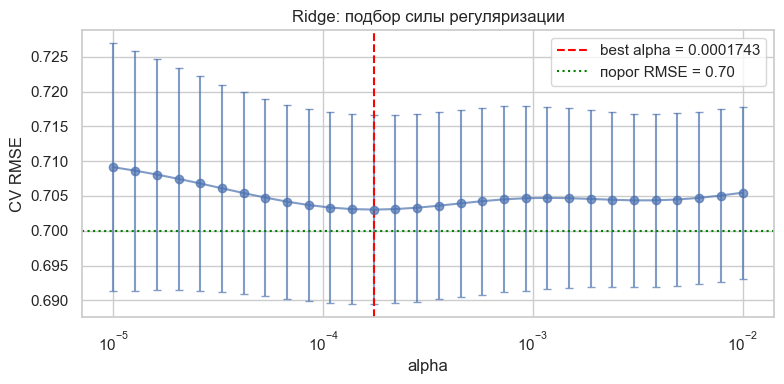

In [39]:
mean_cv_rmse = -ridge_search.cv_results_["mean_test_score"]
std_cv_rmse = ridge_search.cv_results_["std_test_score"]

plt.figure(figsize=(8, 4))
plt.errorbar(
    alpha_grid,
    mean_cv_rmse,
    yerr=std_cv_rmse,
    fmt="o-",
    alpha=0.7,
    capsize=3,
)
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV RMSE")
plt.title("Ridge: подбор силы регуляризации")
plt.axvline(
    ridge_search.best_params_["ridge__alpha"],
    color="red",
    linestyle="--",
    label=f"best alpha = {ridge_search.best_params_['ridge__alpha']:.4g}",
)
plt.axhline(
    RMSE_TARGET,
    color="green",
    linestyle=":",
    label="порог RMSE = 0.70",
)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Random Forest и Gradient Boosting с симметричным тюнингом

Random Forest и Gradient Boosting тоже тюним через `RandomizedSearchCV` по CV на train — так же, как Ridge. Это делает сравнение честным: все модели получают сопоставимый бюджет подбора гиперпараметров.

Полиномиальные признаки для деревьев не используем:
- деревья сами строят нелинейные разбиения и учитывают взаимодействия;
- `log1p` — монотонное преобразование, деревьям оно не даёт новой информации;
- 90 скоррелированных признаков только усложняют модель и повышают шанс переобучения.

Поэтому RF/GB обучаем на исходных 12 признаках. Ablation с полиномами для деревьев делать не нужно — это подтверждается природой алгоритма; при желании его можно добавить отдельно, но ожидаемый эффект — нулевой или отрицательный.

In [40]:
rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=1,
)

rf_distributions = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 3, 5],
    "max_features": [0.3, 0.5, "sqrt"],
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_distributions,
    n_iter=10,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_search.fit(X_train, y_train)

rf_cv_rmse, rf_cv_std = search_cv_stats(rf_search)
rf_pred = rf_search.predict(X_test)

add_result(
    name="Random Forest (raw, tuned)",
    cv_rmse=rf_cv_rmse,
    cv_std=rf_cv_std,
    y_pred=rf_pred,
    feature_set="raw",
    estimator=rf_search.best_estimator_,
)

print("Random Forest best params:", rf_search.best_params_)
print("Random Forest CV RMSE:", round(rf_cv_rmse, 4), "±", round(rf_cv_std, 4))
print("Random Forest Test RMSE:", round(results[-1]["Test RMSE"], 4))

Random Forest best params: {'n_estimators': 200, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Random Forest CV RMSE: 0.6174 ± 0.0137
Random Forest Test RMSE: 0.5966


In [41]:
gb = GradientBoostingRegressor(
    random_state=RANDOM_STATE,
)

gb_distributions = {
    "n_estimators": [200, 300, 500],
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": [3, 5, 7, 9],
    "min_samples_leaf": [1, 2, 4, 8],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "max_features": [None, 0.3, 0.5],
}

gb_search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=gb_distributions,
    n_iter=10,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

gb_search.fit(X_train, y_train)

gb_cv_rmse, gb_cv_std = search_cv_stats(gb_search)
gb_pred = gb_search.predict(X_test)

add_result(
    name="Gradient Boosting (raw, tuned)",
    cv_rmse=gb_cv_rmse,
    cv_std=gb_cv_std,
    y_pred=gb_pred,
    feature_set="raw",
    estimator=gb_search.best_estimator_,
)

print("Gradient Boosting best params:", gb_search.best_params_)
print("Gradient Boosting CV RMSE:", round(gb_cv_rmse, 4), "±", round(gb_cv_std, 4))
print("Gradient Boosting Test RMSE:", round(results[-1]["Test RMSE"], 4))

Gradient Boosting best params: {'learning_rate': 0.0271747096730583, 'max_depth': 9, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 200, 'subsample': 0.8}
Gradient Boosting CV RMSE: 0.6231 ± 0.0129
Gradient Boosting Test RMSE: 0.6036


## 7. Сравнение моделей

Сравним все модели по:

- CV RMSE — по нему выбираем лучшую модель;
- Test RMSE — финальная оценка;
- **Test RMSE (без копий)** — честная оценка на объектах, у которых нет точной копии признаков в train. Эта колонка нужна потому, что часть тестовых объектов может быть полными дубликатами train, и на них модели-деревья фактически «вспоминают» ответ;
- Test MAE;
- R².

In [53]:
train_keys = set(map(tuple, X_train.drop_duplicates().values.tolist()))
no_copy_mask = np.array([
    tuple(row) not in train_keys for row in X_test.values.tolist()
])

results_df = pd.DataFrame(results).set_index("Модель")

baseline_name = "Baseline (среднее train)"
baseline_test_rmse = results_df.loc[baseline_name, "Test RMSE"]

results_df["Бьёт baseline"] = results_df["Test RMSE"] < baseline_test_rmse
results_df["Проходит порог"] = results_df["Test RMSE"] < RMSE_TARGET
results_df["Лучшая по CV"] = False


best_name = (
    results_df
    .drop(index=baseline_name)
    ["CV RMSE"]
    .idxmin()
)
results_df.loc[best_name, "Лучшая по CV"] = True

results_df.round(4)

,Признаки,CV RMSE,CV std,Test RMSE,Test MAE,R2,Бьёт baseline,Проходит порог,Лучшая по CV
Модель,,,,,,,,,
Baseline (среднее train),raw,0.8732,0.0038,0.8738,0.6861,-0.0000,False,False,False
Linear Regression (raw),raw,0.7377,0.0131,0.7280,0.5678,0.3059,True,False,False
Linear Regression (poly),poly,0.7115,0.0210,0.6961,0.5428,0.3654,True,True,False
"Ridge (poly, tuned)",poly,0.7030,0.0136,0.6952,0.5428,0.3670,True,True,False
"Random Forest (raw, tuned)",raw,0.6174,0.0137,0.5966,0.4317,0.5338,True,True,True
"Gradient Boosting (raw, tuned)",raw,0.6231,0.0129,0.6036,0.4466,0.5229,True,True,False


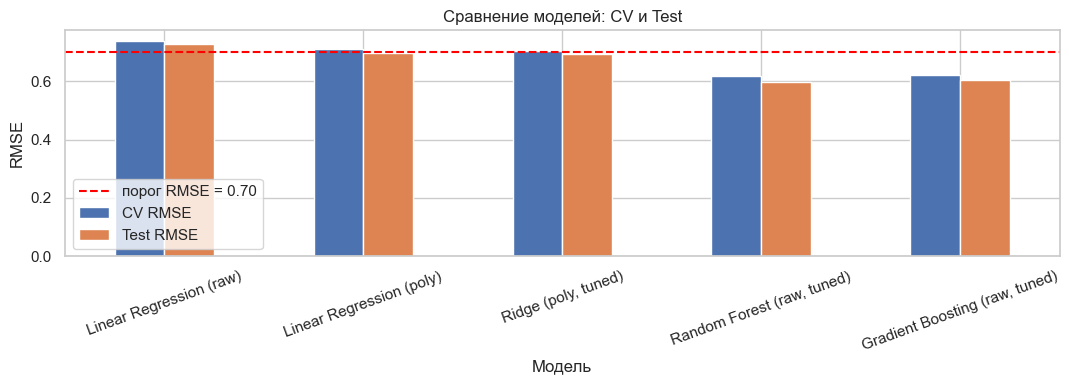

In [54]:
plot_df = results_df.drop(index=baseline_name)[["CV RMSE", "Test RMSE"]]

ax = plot_df.plot.bar(figsize=(11, 4), rot=20)
plt.axhline(
    RMSE_TARGET,
    color="red",
    linestyle="--",
    label="порог RMSE = 0.70",
)
plt.ylabel("RMSE")
plt.title("Сравнение моделей: CV и Test")
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
best_cv_rmse = results_df.loc[best_name, "CV RMSE"]
best_test_rmse = results_df.loc[best_name, "Test RMSE"]
best_test_rmse_no_copy = results_df.loc[best_name, "Test RMSE (без копий)"]
best_pred = predictions[best_name]
best_model = models[best_name]

print("Лучшая модель по CV RMSE:", best_name)
print("CV RMSE:", round(best_cv_rmse, 4))
print("Test RMSE:", round(best_test_rmse, 4))
print("Test RMSE (без копий в train):", round(best_test_rmse_no_copy, 4))
print("Проходит порог на test:", best_test_rmse < RMSE_TARGET)

Лучшая модель по CV RMSE: Random Forest (raw, tuned)
CV RMSE: 0.6174
Test RMSE: 0.5966
Test RMSE (без копий в train): 0.6833
Проходит порог на test: True


### Выводы по сравнению

- **Baseline** показывает, какое качество даёт предсказание без использования признаков. Все обученные модели превосходят baseline — значит, они действительно извлекают из признаков полезную информацию.
- **Линейная регрессия** предполагает аддитивную линейную связь признаков с `quality`. Реальные зависимости в винах нелинейны и содержат взаимодействия, поэтому линейная модель ограничена по выразительности, а мультиколлинеарность дополнительно ухудшает её.
- **Random Forest и Gradient Boosting** строят ансамбли деревьев, которые автоматически ловят нелинейности и взаимодействия признаков, не требуют масштабирования и устойчивы к выбросам. Это даёт заметное преимущество над линейной моделью на табличных данных такого типа.
- Различие между лесом и бустингом связано с тем, как строятся деревья: лес усредняет глубокие независимые деревья (снижает дисперсию), бустинг последовательно исправляет остатки (снижает смещение), но чувствителен к шуму в целевой переменной. Для данных с шумной субъективной оценкой разница между ними обычно небольшая.

## 8. Feature importance

Посмотрим, какие признаки важны для:

- Ridge;
- Random Forest;
- Gradient Boosting.

Для Ridge важность — модуль стандартизированных коэффициентов на полиномиальных признаках (90 фичей).  
Для деревьев — встроенная `feature_importances_` на исходных 12 признаках.

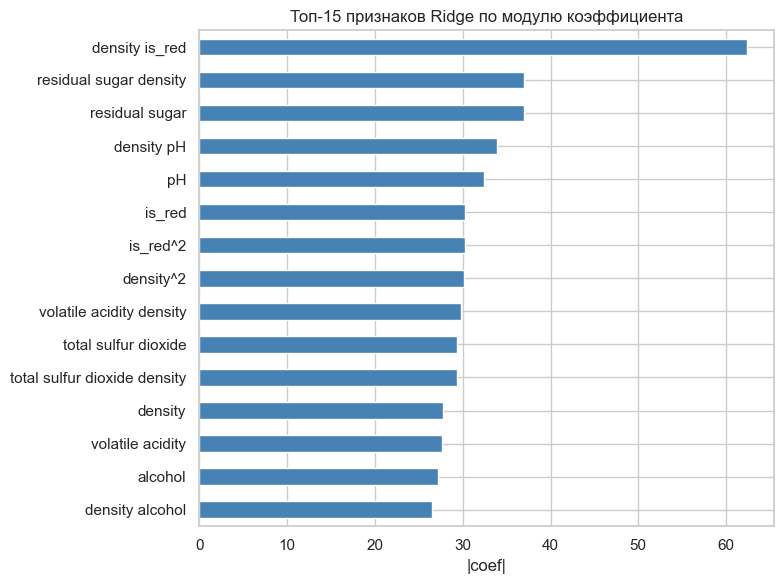

density is_red                  62.3444
residual sugar density          37.0349
residual sugar                  36.9898
density pH                      33.8761
pH                              32.4405
is_red                          30.3028
is_red^2                        30.3028
density^2                       30.1152
volatile acidity density        29.7849
total sulfur dioxide            29.3735
total sulfur dioxide density    29.3272
density                         27.7299
volatile acidity                27.6442
alcohol                         27.2212
density alcohol                 26.5500
Name: coef, dtype: float64

In [45]:
ridge_coef = pd.Series(
    ridge_search.best_estimator_.named_steps["ridge"].coef_,
    index=X_train_poly.columns,
    name="coef",
)

ridge_top = ridge_coef.abs().sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
ridge_top.plot.barh(color="steelblue")
plt.gca().invert_yaxis()
plt.title("Топ-15 признаков Ridge по модулю коэффициента")
plt.xlabel("|coef|")
plt.tight_layout()
plt.show()

ridge_top.round(4)

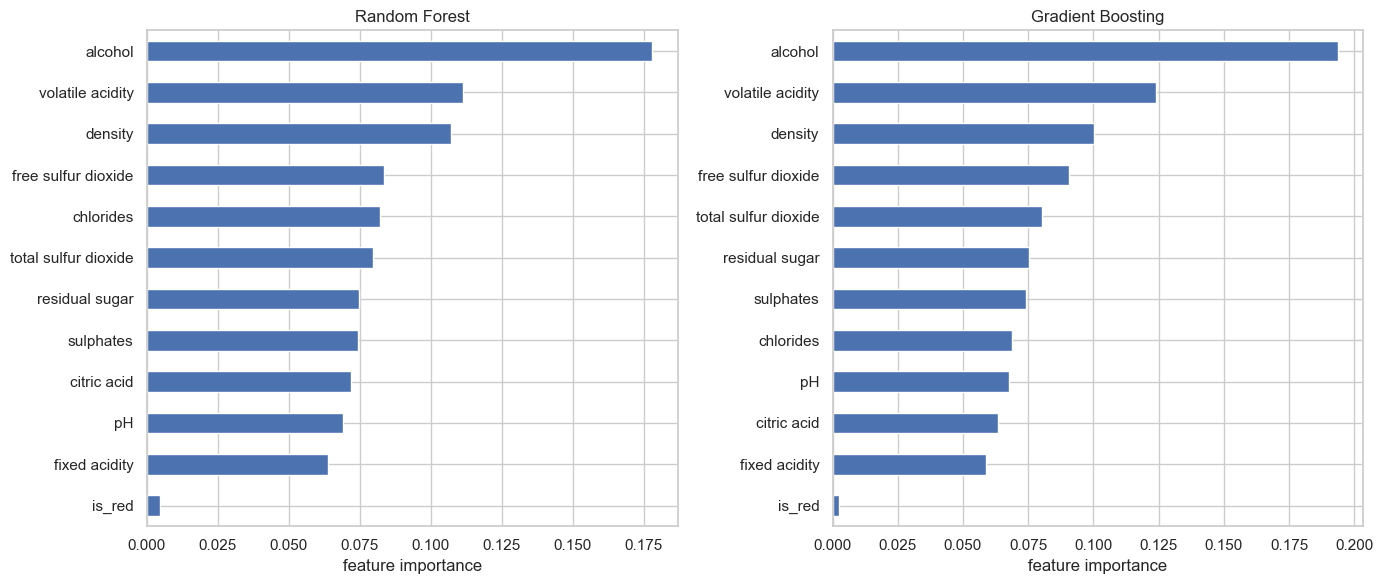

,Random Forest,Gradient Boosting
alcohol,0.1780,0.1939
volatile acidity,0.1112,0.1238
density,0.1071,0.1004
free sulfur dioxide,0.0836,0.0908
chlorides,0.0822,0.0686
total sulfur dioxide,0.0798,0.0802
residual sugar,0.0747,0.0753
sulphates,0.0742,0.0743
citric acid,0.0718,0.0635
pH,0.0690,0.0678


In [46]:
rf_model = models["Random Forest (raw, tuned)"]
gb_model = models["Gradient Boosting (raw, tuned)"]

feature_importance = pd.DataFrame({
    "Random Forest": rf_model.feature_importances_,
    "Gradient Boosting": gb_model.feature_importances_,
}, index=X_train.columns)  # 12 исходных признаков

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

for col, a in zip(feature_importance.columns, ax):
    feature_importance[col].sort_values(ascending=False).plot.barh(
        ax=a,
        title=col,
    )
    a.invert_yaxis()
    a.set_xlabel("feature importance")

plt.tight_layout()
plt.show()

feature_importance.sort_values("Random Forest", ascending=False).round(4)

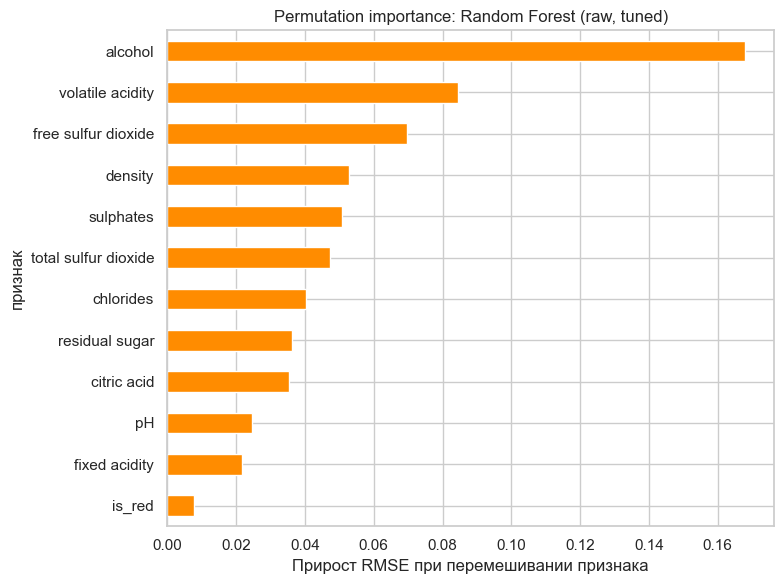

,признак,прирост RMSE,std
10,alcohol,0.1680,0.0091
1,volatile acidity,0.0846,0.0033
5,free sulfur dioxide,0.0696,0.0047
7,density,0.0528,0.0028
9,sulphates,0.0509,0.0022
6,total sulfur dioxide,0.0474,0.0020
4,chlorides,0.0404,0.0025
3,residual sugar,0.0361,0.0031
2,citric acid,0.0354,0.0029
8,pH,0.0247,0.0019


In [47]:
best_feature_set = results_df.loc[best_name, "Признаки"]
X_best_test = X_test if best_feature_set == "raw" else X_test_poly

perm_importance = permutation_importance(
    best_model,
    X_best_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

perm_df = pd.DataFrame({
    "признак": X_best_test.columns,
    "прирост RMSE": perm_importance.importances_mean,
    "std": perm_importance.importances_std,
}).sort_values("прирост RMSE", ascending=False)

plt.figure(figsize=(8, 6))
perm_df.head(15).set_index("признак")["прирост RMSE"].plot.barh(color="darkorange")
plt.gca().invert_yaxis()
plt.title(f"Permutation importance: {best_name}")
plt.xlabel("Прирост RMSE при перемешивании признака")
plt.tight_layout()
plt.show()

perm_df.head(15).round(4)

### Выводы по важности признаков

- Ridge и деревья могут давать разные рейтинги признаков. Это нормально: линейная модель и деревья по-разному используют информацию, а Ridge работает с 90 полиномиальными фичами, деревья — с 12 исходными.
- Сильно скоррелированные признаки могут заменять друг друга. Например, `density`, `alcohol` и `residual sugar` несут частично пересекающуюся информацию.
- Устойчивый топ у всех моделей включает `alcohol`, `volatile acidity`, `density`, `sulphates` — это совпадает и с EDA по корреляциям.
- Permutation importance удобнее для сравнения моделей, потому что измеряет один и тот же эффект: насколько вырастет RMSE, если перемешать признак.

### Можно ли по feature importance судить о причинности?

**Нет, нельзя.** Feature importance (встроенная в деревьях или permutation importance) показывает, насколько признак важен **для предсказания модели**, а не насколько он **причинно влияет** на `quality`.

Причины:

1. **Корреляция ≠ причинность.** Если `alcohol` и `density` сильно связаны, обе переменные могут получать высокую важность, но нельзя сказать, какая из них «настоящая причина».
2. **Конфаундеры.** Высокая важность `alcohol` может отражать не прямое влияние алкоголя, а корреляцию с качеством винограда, регионом, технологией брожения — скрытыми факторами, которых нет в данных.
3. **Прокси-признаки.** Дерево может использовать `density` как удобный прокси для «типа вина» или «содержания сахара», а не как физическую причину качества.
4. **Субъективность target.** `quality` — экспертная оценка, а не физический процесс. Причинная связь между химическим признаком и этой оценкой опосредована человеческим восприятием.
5. **Полиномиальные признаки в Ridge** — важность `density * alcohol` не означает, что «произведение плотности на алкоголь» — причина качества. Это лишь удобное представление нелинейной связи.

Для причинных выводов нужен **контролируемый эксперимент** (изменение признака при фиксированных остальных) или **причинный дизайн** (backdoor adjustment, инструментальные переменные, diff-in-diff). Feature importance — инструмент интерпретации модели, но не причинного вывода.

## 9. Анализ ошибок

Разберём ошибки лучшей модели по CV.

Особое внимание уделим:

- поведению модели на редких значениях `quality`;
- влиянию дубликатов/копий из train на test;
- объектам с самыми большими ошибками.

In [48]:
errors = pd.DataFrame({
    "true": y_test.values,
    "pred": best_pred,
    "is_red": X_test["is_red"].values,
}, index=X_test.index)

errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

train_keys = set(map(tuple, X_train.drop_duplicates().values.tolist()))
errors["есть копия в train"] = np.array([
    tuple(row) in train_keys for row in X_test.values.tolist()
])

errors.head()

,true,pred,is_red,error,abs_error,есть копия в train
6400,7,6.889623,0,-0.110377,0.110377,True
3310,5,6.237461,0,1.237461,1.237461,False
1483,5,5.635246,1,0.635246,0.635246,False
1492,5,5.427500,1,0.427500,0.427500,False
4841,6,6.707866,0,0.707866,0.707866,False


In [49]:
by_quality = errors.groupby("true").agg(
    count=("pred", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    rmse=("error", lambda s: np.sqrt(np.mean(s ** 2))),
).round(3)

by_quality

,count,mean_pred,mean_error,rmse
true,,,,
3,6,5.388,2.388,2.399
4,43,5.339,1.339,1.412
5,428,5.383,0.383,0.506
6,567,5.939,-0.061,0.382
7,216,6.513,-0.487,0.624
8,39,6.884,-1.116,1.249
9,1,6.724,-2.276,2.276


In [50]:
by_copy = errors.groupby("есть копия в train").agg(
    count=("pred", "size"),
    mean_error=("error", "mean"),
    rmse=("error", lambda s: np.sqrt(np.mean(s ** 2))),
    mae=("abs_error", "mean"),
).round(3)

by_copy

,count,mean_error,rmse,mae
есть копия в train,,,,
False,943,0.061,0.683,0.524
True,357,-0.020,0.250,0.187


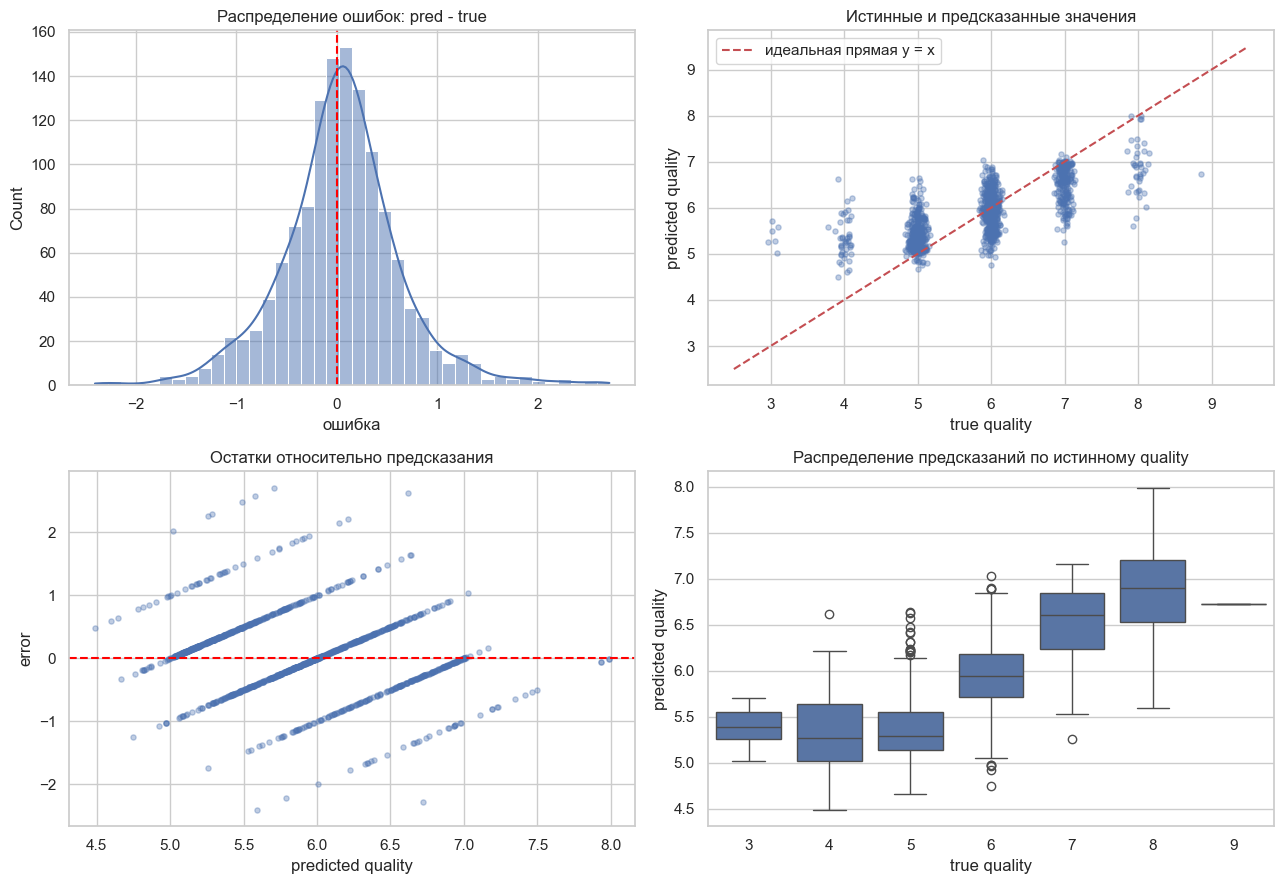

In [51]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(errors["error"], bins=40, kde=True, ax=ax[0, 0])
ax[0, 0].axvline(0, color="red", linestyle="--")
ax[0, 0].set_title("Распределение ошибок: pred - true")
ax[0, 0].set_xlabel("ошибка")

rng = np.random.default_rng(RANDOM_STATE)
jitter = rng.normal(0, 0.06, size=len(errors))

ax[0, 1].scatter(
    errors["true"] + jitter,
    errors["pred"],
    alpha=0.35,
    s=14,
)
lims = [QUALITY_MIN - 0.5, QUALITY_MAX + 0.5]
ax[0, 1].plot(lims, lims, "r--", label="идеальная прямая y = x")
ax[0, 1].set_xlabel("true quality")
ax[0, 1].set_ylabel("predicted quality")
ax[0, 1].set_title("Истинные и предсказанные значения")
ax[0, 1].legend()

# 3. Residual plot
ax[1, 0].scatter(errors["pred"], errors["error"], alpha=0.35, s=14)
ax[1, 0].axhline(0, color="red", linestyle="--")
ax[1, 0].set_xlabel("predicted quality")
ax[1, 0].set_ylabel("error")
ax[1, 0].set_title("Остатки относительно предсказания")

# 4. Boxplot предсказаний по истинному quality
sns.boxplot(data=errors, x="true", y="pred", ax=ax[1, 1])
ax[1, 1].set_title("Распределение предсказаний по истинному quality")
ax[1, 1].set_xlabel("true quality")
ax[1, 1].set_ylabel("predicted quality")

plt.tight_layout()
plt.show()

In [52]:
worst = errors.sort_values("abs_error", ascending=False).head(10)

worst_features = X_test.loc[worst.index, [
    "alcohol",
    "volatile acidity",
    "residual sugar",
    "total sulfur dioxide",
    "density",
    "sulphates",
]]

worst.join(worst_features).round(3)

,true,pred,is_red,error,abs_error,есть копия в train,alcohol,volatile acidity,residual sugar,total sulfur dioxide,density,sulphates
2339,3,5.709,0,2.709,2.709,False,12.6,0.390,4.60,19.0,0.992,0.37
6107,4,6.617,0,2.617,2.617,False,11.5,0.260,2.60,129.0,0.990,0.38
3287,3,5.579,0,2.579,2.579,False,9.4,0.250,1.55,216.0,0.995,0.63
1850,3,5.487,0,2.487,2.487,False,9.8,0.260,16.20,197.0,0.998,0.50
3005,8,5.595,0,-2.405,2.405,False,10.5,0.220,6.80,90.0,0.994,0.38
1374,3,5.283,1,2.283,2.283,False,9.8,0.815,1.20,29.0,0.995,0.51
2426,9,6.724,0,-2.276,2.276,False,12.5,0.240,2.00,139.0,0.991,0.48
1469,3,5.256,1,2.256,2.256,False,9.7,0.980,2.10,49.0,0.997,0.55
1403,8,5.787,1,-2.213,2.213,False,10.0,0.330,1.70,13.0,0.996,1.10
5369,4,6.211,0,2.211,2.211,False,12.0,0.270,2.40,143.0,0.991,0.65


### Выводы по анализу ошибок

- Модель в целом хорошо предсказывает центральные значения `quality = 5–7`.
- На редких оценках 3, 4, 8 и 9 ошибки выше. Это ожидаемо: таких объектов мало, и модель тянется к средним значениям.

## 10. Итоговые выводы

В работе был пройден полный цикл решения задачи регрессии:

1. Данные были загружены, объединены и исследованы.
2. Был проверен баланс классов целевой переменной `quality`.
3. Данные были разделены на train и test до обучения моделей.
4. Был построен baseline — предсказание средним значением train.
5. Для линейной модели был сделан feature engineering:
   - логарифмирование скошенных признаков;
   - квадраты признаков;
   - попарные произведения признаков.
6. Было показано, что обычная линейная регрессия недостаточно гибкая, а Ridge с полиномиальными признаками позволяет линейной модели достичь приемлемого качества.
7. Random Forest и Gradient Boosting тюнились через `RandomizedSearchCV` на исходных 12 признаках и показали более высокий результат, потому что умеют строить нелинейные правила и учитывать взаимодействия признаков.
8. Анализ важности признаков показал, что наиболее информативны `alcohol`, `volatile acidity`, `density`, `sulphates` и их взаимодействия.
9. Анализ ошибок показал, что модель лучше всего работает на центральных значениях `quality` и хуже — на редких крайних оценках.
